In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
DATA_PATH = Path("../data/processed/cleaned_reviews.csv")

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)

df.head()

Dataset shape: (22641, 14)


,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name,Sentiment,Combined_Review,Cleaned_Review,Processed_Review
0,767,33,NaN,Absolutely wonderful - silky and sexy and comf...,4,1,0,Initmates,Intimate,Intimates,Positive,Absolutely wonderful - silky and sexy and comf...,absolutely wonderful silky and sexy and comfor...,absolutely wonderful silky sexy comfortable
1,1080,34,NaN,Love this dress! it's sooo pretty. i happene...,5,1,4,General,Dresses,Dresses,Positive,Love this dress! it's sooo pretty. i happene...,love this dress its sooo pretty i happened to ...,love dress sooo pretty happened find store im ...
2,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,3,0,0,General,Dresses,Dresses,Neutral,Some major design flaws I had such high hopes ...,some major design flaws i had such high hopes ...,major design flaw high hope dress really wante...
3,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5,1,0,General Petite,Bottoms,Pants,Positive,"My favorite buy! I love, love, love this jumps...",my favorite buy i love love love this jumpsuit...,favorite buy love love love jumpsuit fun flirt...
4,847,47,Flattering shirt,This shirt is very flattering to all due to th...,5,1,6,General,Tops,Blouses,Positive,Flattering shirt This shirt is very flattering...,flattering shirt this shirt is very flattering...,flattering shirt shirt flattering due adjustab...


In [3]:
X = df['Processed_Review']

y = df['Sentiment']

print("Input shape:", X.shape)
print("Target shape:", y.shape)

print("\nSentiment distribution:")
print(y.value_counts())

Input shape: (22641,)
Target shape: (22641,)

Sentiment distribution:
Sentiment
Positive    17448
Neutral      2823
Negative     2370
Name: count, dtype: int64


In [4]:
print("Missing values in X:", X.isna().sum())

print(
    "Empty reviews:",
    (X.str.strip() == '').sum()
)

print("\nMissing values in y:", y.isna().sum())

Missing values in X: 0
Empty reviews: 0

Missing values in y: 0


# Train-Test Split

In [5]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 18112
Testing samples: 4529


In [6]:
print("Training distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training distribution:
Sentiment
Positive    77.064929
Neutral     12.466873
Negative    10.468198
Name: proportion, dtype: float64

Testing distribution:
Sentiment
Positive    77.058953
Neutral     12.475160
Negative    10.465887
Name: proportion, dtype: float64


# Text Vectorization using TF-IDF

In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95
)

In [8]:
X_train_tfidf = tfidf.fit_transform(X_train)

print("Training TF-IDF shape:", X_train_tfidf.shape)

Training TF-IDF shape: (18112, 10000)


In [9]:
X_test_tfidf = tfidf.transform(X_test)

print("Testing TF-IDF shape:", X_test_tfidf.shape)

Testing TF-IDF shape: (4529, 10000)


In [10]:
feature_names = tfidf.get_feature_names_out()

print("Total features:", len(feature_names))

print("\nFirst 30 features:")
print(feature_names[:30])

Total features: 10000

First 30 features:
['aa' 'ability' 'able' 'able get' 'able order' 'able pull' 'able size'
 'able try' 'able wear' 'absolute' 'absolutely' 'absolutely adorable'
 'absolutely adore' 'absolutely beautiful' 'absolutely fell'
 'absolutely gorgeous' 'absolutely love' 'absolutely loved'
 'absolutely no' 'absolutely not' 'absolutely perfect'
 'absolutely stunning' 'abt' 'accent' 'accentuate' 'accentuated'
 'accentuates' 'acceptable' 'accessorize' 'accessory']


# Model Training

In [11]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression

In [12]:
nb_model=MultinomialNB()

nb_model.fit(X_train_tfidf,y_train)

y_pred_nb = nb_model.predict(X_test_tfidf)

print("First 20 Actual Labels:")
print(y_test[:20].values)

print("\nFirst 20 Predicted Labels:")
print(y_pred_nb[:20])

First 20 Actual Labels:
<ArrowStringArray>
['Positive', 'Positive', 'Positive', 'Positive', 'Positive', 'Positive',
  'Neutral', 'Negative', 'Positive',  'Neutral', 'Positive', 'Positive',
 'Positive', 'Positive', 'Positive', 'Positive', 'Positive', 'Positive',
 'Positive', 'Positive']
Length: 20, dtype: str

First 20 Predicted Labels:
['Positive' 'Positive' 'Positive' 'Positive' 'Positive' 'Positive'
 'Positive' 'Positive' 'Positive' 'Positive' 'Positive' 'Positive'
 'Positive' 'Positive' 'Positive' 'Positive' 'Positive' 'Positive'
 'Positive' 'Positive']


In [13]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

nb_accuracy = accuracy_score(y_test, y_pred_nb)

print("Naive Bayes Accuracy:", round(nb_accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_nb))

Naive Bayes Accuracy: 80.04 %

Classification Report:
              precision    recall  f1-score   support

    Negative       0.75      0.20      0.31       474
     Neutral       0.48      0.11      0.17       565
    Positive       0.81      0.99      0.89      3490

    accuracy                           0.80      4529
   macro avg       0.68      0.43      0.46      4529
weighted avg       0.76      0.80      0.74      4529



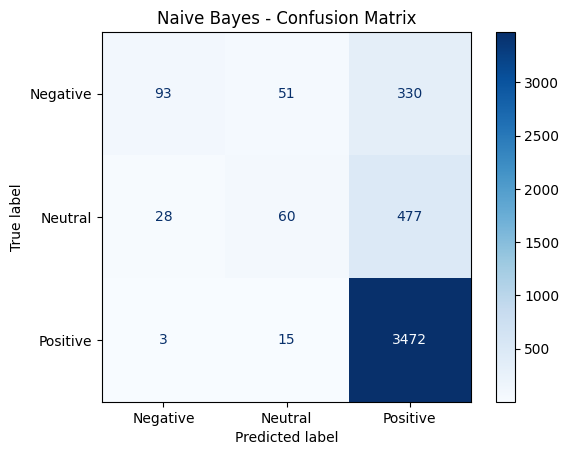

In [14]:
cm = confusion_matrix(
    y_test,
    y_pred_nb,
    labels=['Negative', 'Neutral', 'Positive']
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Negative', 'Neutral', 'Positive']
)

disp.plot(cmap='Blues', values_format='d')
plt.title("Naive Bayes - Confusion Matrix")
plt.show()

# Logistic Regression

In [15]:
lr_model=LogisticRegression(max_iter=1000)

In [16]:
lr_model.fit(X_train_tfidf,y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mul

In [17]:
y_pred_lr = lr_model.predict(X_test_tfidf)

print("First 20 Actual Labels:")
print(y_test[:20].values)

print("\nFirst 20 Predicted Labels:")
print(y_pred_lr[:20])


First 20 Actual Labels:
<ArrowStringArray>
['Positive', 'Positive', 'Positive', 'Positive', 'Positive', 'Positive',
  'Neutral', 'Negative', 'Positive',  'Neutral', 'Positive', 'Positive',
 'Positive', 'Positive', 'Positive', 'Positive', 'Positive', 'Positive',
 'Positive', 'Positive']
Length: 20, dtype: str

First 20 Predicted Labels:
['Positive' 'Positive' 'Positive' 'Positive' 'Positive' 'Positive'
 'Positive' 'Negative' 'Positive' 'Positive' 'Positive' 'Positive'
 'Positive' 'Positive' 'Positive' 'Positive' 'Positive' 'Positive'
 'Positive' 'Positive']


In [18]:
lr_accuracy = accuracy_score(y_test, y_pred_lr)

print("Logistic Regression Accuracy:", round(lr_accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))

Logistic Regression Accuracy: 83.55 %

Classification Report:
              precision    recall  f1-score   support

    Negative       0.66      0.51      0.57       474
     Neutral       0.47      0.25      0.32       565
    Positive       0.88      0.98      0.93      3490

    accuracy                           0.84      4529
   macro avg       0.67      0.58      0.61      4529
weighted avg       0.81      0.84      0.81      4529



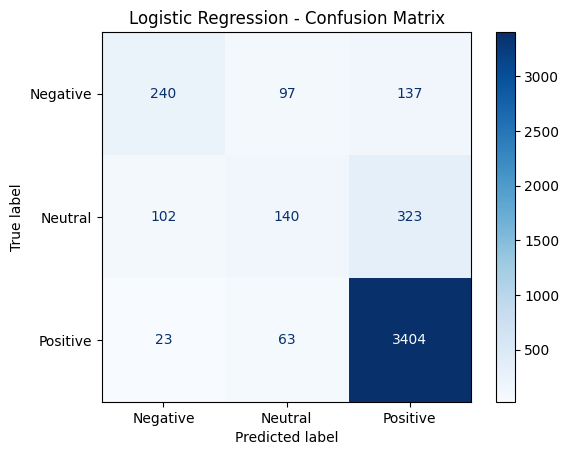

In [19]:
cm_lr = confusion_matrix(
    y_test,
    y_pred_lr,
    labels=['Negative', 'Neutral', 'Positive']
)

disp_lr = ConfusionMatrixDisplay(
    confusion_matrix=cm_lr,
    display_labels=['Negative', 'Neutral', 'Positive']
)

disp_lr.plot(cmap='Blues', values_format='d')
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

In [20]:
lr_balanced = LogisticRegression(
    max_iter=1000,
    class_weight='balanced'
)

In [21]:
lr_balanced.fit(X_train_tfidf, y_train)

y_pred_balanced = lr_balanced.predict(X_test_tfidf)

print("Balanced Logistic Regression Accuracy:",
      round(accuracy_score(y_test, y_pred_balanced) * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_balanced))

Balanced Logistic Regression Accuracy: 80.81 %

Classification Report:
              precision    recall  f1-score   support

    Negative       0.54      0.65      0.59       474
     Neutral       0.38      0.53      0.44       565
    Positive       0.96      0.88      0.92      3490

    accuracy                           0.81      4529
   macro avg       0.63      0.68      0.65      4529
weighted avg       0.85      0.81      0.82      4529



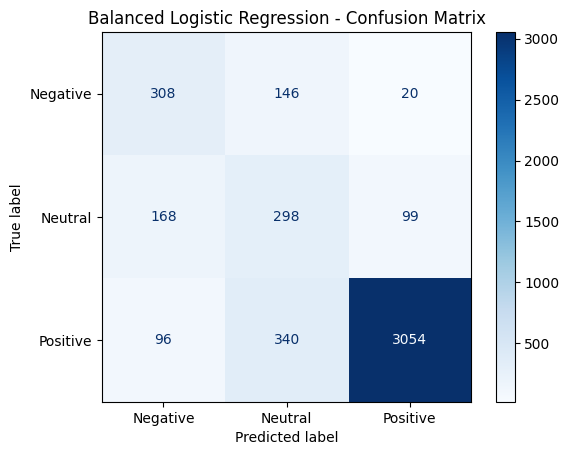

In [22]:
cm_balanced = confusion_matrix(
    y_test,
    y_pred_balanced,
    labels=['Negative', 'Neutral', 'Positive']
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_balanced,
    display_labels=['Negative', 'Neutral', 'Positive']
)

disp.plot(cmap='Blues', values_format='d')
plt.title("Balanced Logistic Regression - Confusion Matrix")
plt.show()

In [ ]:
models = {
    'Naive Bayes': y_pred_nb,
    'Logistic Regression': y_pred_lr,
    'Balanced Logistic Regression': y_pred_balanced
}

results = []

for model_name, predictions in models.items():
    report = classification_report(
        y_test,
        predictions,
        output_dict=True
    )

    results.append({
        'Model': model_name,
        'Accuracy': accuracy_score(y_test, predictions),
        'Macro F1': report['macro avg']['f1-score'],
        'Weighted F1': report['weighted avg']['f1-score']
    })

model_comparison = pd.DataFrame(results)

model_comparison.round(2)

,Model,Accuracy,Macro F1,Weighted F1
0,Naive Bayes,0.80,0.46,0.74
1,Logistic Regression,0.84,0.61,0.81
2,Balanced Logistic Regression,0.81,0.65,0.82


# Error Analysis

In [24]:
error_df = pd.DataFrame({
    'Review': X_test,
    'Actual': y_test,
    'Predicted': y_pred_balanced
})

error_df = error_df[
    error_df['Actual'] != error_df['Predicted']
].copy()

print("Total incorrect predictions:", len(error_df))

error_df.head(10)

Total incorrect predictions: 869


,Review,Actual,Predicted
15353,stretch stretch fast lb order size usually siz...,Neutral,Negative
902,pretty pattern weird texture love design patte...,Positive,Neutral
8121,beautiful youre tall enough pant really beauti...,Neutral,Positive
16101,cute love shirt black larger chest not feel li...,Positive,Neutral
18803,cute print lacking shape print attracted dress...,Positive,Negative
17534,disappointing really wanted love dress thought...,Neutral,Negative
2668,seeeee thru baggy regular size happens good th...,Neutral,Positive
3313,classic like jacket neutral color classic cut ...,Positive,Negative
5670,top gorgeous person got small pound f chest ne...,Positive,Neutral
17420,whimsical cute blouse get lot compliment bough...,Neutral,Positive


In [25]:
error_df.groupby(
    ['Actual', 'Predicted']
).size().reset_index(name='Count').sort_values(
    by='Count',
    ascending=False
)

,Actual,Predicted,Count
5,Positive,Neutral,340
2,Neutral,Negative,168
0,Negative,Neutral,146
3,Neutral,Positive,99
4,Positive,Negative,96
1,Negative,Positive,20


# Sentiment Analysis – Key Findings

## 1. TF-IDF Feature Extraction
- Converted review text into numerical features using TF-IDF.
- Used unigrams and bigrams to capture individual words and word combinations.
- Selected 10,000 features for model training.

## 2. Model Training
Three machine learning models were trained and evaluated:

- Multinomial Naive Bayes
- Logistic Regression
- Balanced Logistic Regression

## 3. Model Performance Comparison

| Model | Accuracy | Macro F1 | Weighted F1 |
|---|---:|---:|---:|
| Naive Bayes | 79.91% | 0.45 | 0.74 |
| Logistic Regression | 83.59% | 0.61 | 0.81 |
| Balanced Logistic Regression | 80.86% | 0.65 | 0.82 |

## 4. Selected Model

**Balanced Logistic Regression** was selected as the best-performing model based on its Macro F1-score.

| Metric | Score |
|---|---:|
| Accuracy | 80.86% |
| Macro F1-score | 0.65 |
| Weighted F1-score | 0.82 |
| Negative Recall | 0.66 |
| Neutral Recall | 0.52 |
| Positive Recall | 0.87 |

## 5. Key Observations

- Class imbalance affected the performance of the initial models.
- Using `class_weight='balanced'` improved the identification of minority classes.
- Negative and Neutral recall improved significantly with Balanced Logistic Regression.
- Positive reviews were frequently misclassified as Neutral.
- Error analysis helped identify common prediction mistakes.

## 6. Dataset Limitation

Sentiment labels were derived from customer ratings rather than manually annotated review text.

- Ratings 1–2: Negative
- Rating 3: Neutral
- Ratings 4–5: Positive

Therefore, rating-derived labels may not always represent the actual sentiment expressed in the review text.

## 7. Conclusion

Balanced Logistic Regression achieved the highest Macro F1-score of 0.65 among the evaluated models. It provided a better balance across the three sentiment classes compared to the other models.

The trained model and TF-IDF vectorizer will be saved for future sentiment predictions and integration into the ReviewIQ application.

# Save the trained model

In [26]:
import joblib

In [27]:
MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

In [28]:
joblib.dump(lr_balanced, MODEL_DIR / "sentiment_model.pkl")

joblib.dump(tfidf, MODEL_DIR / "tfidf_vectorizer.pkl")

print("Model and vectorizer saved successfully!")

Model and vectorizer saved successfully!
